# Chapter 5: Pretraining on unlabeled data
This chapter covers the training and evaluation of a GPT model. It also looks at loading pretrained weights from OpenAI

### 5.1 Evaluating Generative Text Models
This chapter looks at how we can evaluate text generartion models

In [7]:
import tiktoken
import sys
sys.path.append("..")
from src.classes import *

In [39]:
%load_ext autoreload
%autoreload 2

In [6]:
GPT_CONFIG_124M = {
    'vocab_size': 50257,
    'context_length': 256,
    'emb_dim': 768,
    'n_heads': 12,
    'n_layers': 12,
    'drop_rate_embedding': 0.1,
    'drop_rate_shortcut': 0.1,
    'drop_rate_multihead': 0.1,
    'qkv_bias': False,
    }

def generate_text_simple(model, idx, max_new_tokens, context_size):
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :] # Focus only on last timestep, so that (batch, n_token, vocab_size) -> (batch, vocab_size)
        probas = torch.softmax(logits, dim=-1) # Probabilities for token being a word in vocab
        idx_next = torch.argmax(probas, dim=-1, keepdim=True) # Find token with highest probability
        idx = torch.cat((idx, idx_next), dim=1) # Add token at last place in sequence for next prediction

    return idx

In [ ]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.eval()

In [10]:
# Create functions for encoding and decoding
def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(text, allowed_special={'<|endoftext|>'})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0) # Adds batch dimension to tensor
    return encoded_tensor

def token_ids_to_text(token_ids, tokenizer):
    flat = token_ids.squeeze(0) # Remove batch dimension
    return tokenizer.decode(flat.tolist())


In [13]:
start_context = "Every effort moves you"
tokenizer = tiktoken.get_encoding("gpt2")

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids(start_context, tokenizer),
    max_new_tokens=10,
    context_size=GPT_CONFIG_124M["context_length"]
    )

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you rentingetic wasnم refres RexMeCHicular stren


#### 5.1.2 Calculating the Text Generation Loss
Since we haven't trained the model yet it clearly fails to output coherent text. For training it we need to measure the text generation loss, to see how the model behaves during training and if it's learning anything.

In [17]:
inputs = torch.tensor([[16833, 3626, 6100],  # ["every effort moves",
                       [40, 1107, 588]])     # "I really like"]

targets = torch.tensor([[3626, 6100, 345 ],  # [" effort moves you",
                        [1107, 588, 11311]]) # " really like chocolate"]

with torch.no_grad(): # Feed input into model to calculate logits
    logits = model(inputs)

probas = torch.softmax(logits, dim=-1) # Probability of each token in vocab
print(probas.shape)
token_ids = torch.argmax(probas, dim=-1, keepdim=True) # Get tokenID for higest scoring probability
print("Token IDs:\n", token_ids)

# Convert back into text
print(f"Targets batch 1: {token_ids_to_text(targets[0], tokenizer)}")
print(f"Outputs batch 1:"
 f" {token_ids_to_text(token_ids[0].flatten(), tokenizer)}")

torch.Size([2, 3, 50257])
Token IDs:
 tensor([[[16657],
         [  339],
         [42826]],

        [[49906],
         [29669],
         [41751]]])
Targets batch 1:  effort moves you
Outputs batch 1:  Armed heNetflix


In [19]:
# Initial softmax scores for target tokens
text_idx = 0
target_probas_1 = probas[text_idx, [0, 1, 2], targets[text_idx]]
print("Text 1:", target_probas_1)

text_idx = 1
target_probas_2 = probas[text_idx, [0, 1, 2], targets[text_idx]]
print("Text 2:", target_probas_2)

Text 1: tensor([7.4514e-05, 3.1054e-05, 1.1567e-05])
Text 2: tensor([1.0343e-05, 5.6737e-05, 4.7620e-06])


In [24]:
log_probas = torch.log(torch.cat((target_probas_1, target_probas_2)))
print(log_probas)
avg_log_probas = torch.mean(log_probas)
print("Avergare loss score:", avg_log_probas)
neg_avg_log_probas = avg_log_probas * -1
print("Cross entropy loss", neg_avg_log_probas)

# Cross entropy measures the difference between two probability distributions, typically true distributions (tokens in dataset) vs predicted distribution.

tensor([ -9.5045, -10.3798, -11.3674, -11.4792,  -9.7771, -12.2549])
Avergare loss score: tensor(-10.7938)
Cross entropy loss tensor(10.7938)


In [27]:
print("Logits shape:", logits.shape)        # (batch, num_tokens, vocab_size)
print("Targets shape:", targets.shape)      # (batch, num_tokens)

Logits shape: torch.Size([2, 3, 50257])
Targets shape: torch.Size([2, 3])


In [26]:
# Since the logits and targets have different dimensions we need to flatten them over the batch dimension
logits_flat = logits.flatten(0, 1)
targets_flat = targets.flatten()
print("Flattened logits:", logits_flat.shape)
print("Flattened targets:", targets_flat.shape)

Flattened logits: torch.Size([6, 50257])
Flattened targets: torch.Size([6])


In [28]:
# Calculate cross entropy loss using Pytorch function
loss = torch.nn.functional.cross_entropy(logits_flat, targets_flat)
print(loss)

tensor(10.7938)


In [ ]:
"""
Another measurement commonly used for measuring performance in language models is Perplexity. 
Perplexity measures how well the probability distribution predicted by the model matches the actual distribution of words in the datset.
It can be calculated using: perplexity = torch.exp(loss)
"""

#### 5.1.3 Calculating the Training and Validation set Losses

In [30]:
file_path = "C:\\Users\\gusta\\build-an-LLM\\build-a-llm-Raschka\\ch02\\the-verdict.txt"
with open(file_path, "r", encoding="utf-8") as f:
    text_data = f.read()

In [32]:
total_characters = len(text_data)
total_tokens = len(tokenizer.encode(text_data))
print(f"Total amount of characters: {total_characters}")
print(f"Total amount of tokens: {total_tokens}")

Total amount of characters: 20479
Total amount of tokens: 5145


In [34]:
# Split data into training and validation sets
train_ratio = 0.9
split_idx   = int(train_ratio * len(text_data))
train_data  = text_data[:split_idx]
val_data    = text_data[split_idx:]

In [42]:
# Dataloader from chapter 2
from torch.utils.data import DataLoader
from src.classes import GPTDatasetV1


def create_dataloader_v1(txt, batch_size=4, max_length=256, stride=128,
                        shuffle=True, drop_last=True, num_workers=0):
    """Function that uses GPTDatasetV1 to load the inputs in batches via a Pytorch DataLoader"""
    tokenizer = tiktoken.get_encoding("gpt2") # Initialize tokenizer

    # Create dataset
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)

    # Create dataloader
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers
    )

    return dataloader

In [43]:
torch.manual_seed(123)

train_loader = create_dataloader_v1(
    train_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=True,
    shuffle=True,
    num_workers=0
)

val_loader = create_dataloader_v1(
    val_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=False,
    shuffle=False,
    num_workers=0
)

In [44]:
print("Train loader:")
for x,y in train_loader:
    print(x.shape, y.shape)

print("\nValidation loader:")
for x,y in val_loader:
    print(x.shape, y.shape)

Train loader:
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])

Validation loader:
torch.Size([2, 256]) torch.Size([2, 256])


In [46]:
def calc_loss_batch(input_batch, target_batch, model, device):
    """Function that calclulates cross entropy loss of a given batch"""
    input_batch  = input_batch.to(device) # So we can use GPU for calculations
    target_batch = target_batch.to(device)

    logits = model(input_batch)
    loss   = torch.nn.functional.cross_entropy(
        logits.flatten(0, 1), target_batch.flatten()
    )
    return loss

def calc_loss_loader(data_loader, model, device, num_batches=None):
    """Function that calclulates average cross entropy loss over all batches"""
    total_loss = 0

    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader) # Iterates over all batches if not specified
    else:
        num_batches = min(num_batches, len(data_loader)) # Reduces the number of batches to match the total number of batches in loader (i.e. can't have a number > number of batches)

    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()
        else:
            break
    return total_loss / num_batches

In [47]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu") # Use GPU if possible
model.to(device)
with torch.no_grad():
    train_loss  = calc_loss_loader(train_loader, model, device)
    val_loss    = calc_loss_loader(val_loader, model, device)

print(f"Training loss: {train_loss:3f} and validation loss: {val_loss:3f}")

Training loss: 10.987385 and validation loss: 10.980906


### 5.2 Trainin an LLM
Now that the loss functions are created we can start training the model.

In [49]:
# Simple training function

def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs, eval_freq, eval_iter, start_context, tokenizer):
    train_losses, val_losses, track_tokens_seen = [], [], []
    tokens_seen, global_step = 0, -1

    for epoch in range(num_epochs):
        model.train()                   # set to train so that we can update weights

        for input_batch, target_batch in train_loader:
            optimizer.zero_grad()       # Resets loss gradients from the previous batch iteration
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            loss.backward()             # Calculate loss gradients
            optimizer.step()            # Update model weights using loss gradients
            tokens_seen += input_batch.numel()
            global_step += 1

            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter
                )
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                    f"Train loss {train_loss:.3f}, "
                    f"Val loss {val_loss:.3f}")

        generate_and_print_sample(model, tokenizer, device, start_context)

    return train_losses, val_losses, track_tokens_seen

def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    """Function that evaluates the model on the validation set"""
    model.eval()        # Set model to eval mode to not update parameters

    with torch.no_grad():
        train_loss  = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
        val_loss    = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
    model.train()       # Set model to train mode again 
    return train_loss, val_loss

def generate_and_print_sample(model, tokenizer, device, start_context):
    """Function that is used to generate and print some text for tracking if model improves during training."""
    model.eval()
    context_size = model.pos_emb.weight.shape[0]
    encoded      = text_to_token_ids(start_context, tokenizer).to(device)
    with torch.no_grad():
        token_ids = generate_text_simple(model=model, idx=encoded, max_new_tokens=50, context_size=context_size)
    decoded_text = token_ids_to_text(token_ids, tokenizer)
    print(decoded_text.replace("\n", " "))
    model.train()

In [50]:
# Train using AdamW optimizer
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0004, weight_decay=0.1)

num_epochs = 10
train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device, num_epochs=num_epochs, eval_freq=5,
    eval_iter=5, start_context="Every effort moves you", tokenizer=tokenizer
)

Ep 1 (Step 000000): Train loss 9.782, Val loss 9.934
Ep 1 (Step 000005): Train loss 8.112, Val loss 8.340
Every effort moves you,,,,,,,,,,,,.                                     
Ep 2 (Step 000010): Train loss 6.662, Val loss 7.049
Ep 2 (Step 000015): Train loss 5.961, Val loss 6.616
Every effort moves you, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and,, and, and,
Ep 3 (Step 000020): Train loss 5.717, Val loss 6.594
Ep 3 (Step 000025): Train loss 5.210, Val loss 6.355
Every effort moves you, and I had been.                                            
Ep 4 (Step 000030): Train loss 4.427, Val loss 6.279
Ep 4 (Step 000035): Train loss 4.075, Val loss 6.227
Every effort moves you know the                          "I he had the donkey and I had the and I had the donkey and down the room, I had
Ep 5 (Step 000040): Train loss 3.737, Val loss 6.160
Every effort moves you know it was not that the picture--I had the fact by the last

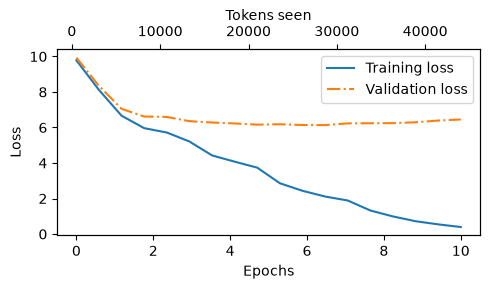

In [51]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
 fig, ax1 = plt.subplots(figsize=(5, 3))
 ax1.plot(epochs_seen, train_losses, label="Training loss")
 ax1.plot(
 epochs_seen, val_losses, linestyle="-.", label="Validation loss"
 )
 ax1.set_xlabel("Epochs")
 ax1.set_ylabel("Loss")
 ax1.legend(loc="upper right")
 ax1.xaxis.set_major_locator(MaxNLocator(integer=True))
 ax2 = ax1.twiny()
 ax2.plot(tokens_seen, train_losses, alpha=0)
 ax2.set_xlabel("Tokens seen")
 fig.tight_layout()
 plt.show()
epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)

In [ ]:
# From the plot we can see that the model is overfitting and memorizing the training data. Not unsurprising since small dataset and multiple epochs

### 5.3 Decoding Strategies to Control Randomness
Some strategies to generate more original text